# FinBERT CNN baseline and hard mask

Trains the frozen FinBERT CNN baseline and gets class probabilities for every sentence. Then saves the hard mask (top softmax probability) and the all-agree flag.


## Imports

In [21]:
import os
os.environ["HF_HOME"] = os.path.abspath("../.cache/huggingface")
os.environ["HF_HUB_CACHE"] = os.path.abspath("../.cache/huggingface/hub")
os.makedirs(os.environ["HF_HUB_CACHE"], exist_ok=True)
import sys

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from tensorflow import keras

sys.path.append("..")
from utils import finbert_cnn
from utils.finbert_cnn import BASELINE_SEED, load_finbert_inputs, train_baseline
from utils.preprocessing import LABELS, encode_labels

keras.utils.set_random_seed(BASELINE_SEED)


## Load FinBERT embeddings and tokenize

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")
y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

X_train, X_val, X_test, embedding_matrix = load_finbert_inputs(train_df, val_df, test_df)
print(X_train.shape, X_val.shape, X_test.shape, embedding_matrix.shape)


/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1105 10:30:11.360000 11358 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 40363.00it/s]
[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | U

(2901, 64) (967, 64) (968, 64) (30873, 768)


## Evaluation helper (CNN: `utils.finbert_cnn.build_cnn`)

In [3]:
def evaluate(model, X, y, name):
    probabilities = model.predict(X, batch_size=32, verbose=0)
    predictions = probabilities.argmax(axis=1)
    print(name)
    print("Accuracy:", accuracy_score(y, predictions))
    print("Macro F1:", f1_score(y, predictions, average="macro"))
    print(classification_report(y, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y, predictions, display_labels=LABELS)
    return probabilities, predictions


## Train the baseline

In [4]:
baseline_model = train_baseline(embedding_matrix, X_train, y_train, X_val, y_val)


Epoch 1/20
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5882 - loss: 0.9495 - val_macro_f1: 0.3184
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5888 - loss: 0.9485 - val_accuracy: 0.6236 - val_loss: 0.8556 - val_macro_f1: 0.3184
Epoch 2/20
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6399 - loss: 0.8319 - val_macro_f1: 0.4151
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6412 - loss: 0.8309 - val_accuracy: 0.6784 - val_loss: 0.7745 - val_macro_f1: 0.4151
Epoch 3/20
87/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6832 - loss: 0.7568 - val_macro_f1: 0.4368
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6880 - loss: 0.7501 - val_accuracy: 0.6939 - val_loss: 0.7141 - val_macro_f1: 0.4368
Epoch 4/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7218 - loss: 0.6512 - val_macro_f1: 0.5897
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7218 - loss: 0.6512 - val_accuracy: 0.7332 - val_loss: 0.6519 - val_macro_f1: 0.5897
Epoch 5/20
8

## Mark hard examples

In [ ]:
oof_probabilities = finbert_cnn.oof_probabilities(embedding_matrix, X_train, y_train)
val_probabilities = baseline_model.predict(X_val, batch_size=32, verbose=0)
test_probabilities = baseline_model.predict(X_test, batch_size=32, verbose=0)


## Save baseline probabilities

One row per sentence with the three class probabilities. Train uses the out-of-fold probabilities, so no train sentence is scored by a model that saw it.

In [15]:
PROB_COLS = [f"p_{label}" for label in LABELS]

def probability_frame(df, probabilities):
    out = df[["sentence", "label"]].copy()
    out[PROB_COLS] = probabilities
    out["pred"] = [LABELS[i] for i in probabilities.argmax(axis=1)]
    out["max_prob"] = probabilities.max(axis=1)
    return out

frames = {
    "train": probability_frame(train_df, oof_probabilities),
    "val": probability_frame(val_df, val_probabilities),
    "test": probability_frame(test_df, test_probabilities),
}
frames


{'train':                                                sentence     label  p_negative  \
 0     The fair value of the company 's investment pr...  negative    0.903733   
 1     Trading under the name Velta UK , a former Upo...   neutral    0.026475   
 2     Via the move , the company aims annual savings...  positive    0.144699   
 3     The company also estimates the already carried...  positive    0.013724   
 4     However , the proportion of the paid standing ...  positive    0.001686   
 ...                                                 ...       ...         ...   
 2896  The event can also be viewed as a live webcast...   neutral    0.002633   
 2897  Finnish waste management and cleaning group La...  negative    0.938475   
 2898  4 ) Complete name of the shareholder : Otto He...   neutral    0.012595   
 2899  Global Markets Direct 's Pohjola Bank plc - Fi...   neutral    0.002357   
 2900  Metso will supply the equipment for two proces...  positive    0.010960   
 
     

## Hard mask: confidence band

A sentence is hard when the baseline's top softmax probability falls inside `[BAND_LOW, BAND_HIGH]`. If train has fewer than `MIN_TRAIN_HARD` hard rows, the band is widened in steps of 0.05, using train only. The band chosen on train is then applied unchanged to val and test.

In [16]:
BAND_LOW, BAND_HIGH = 0.4, 0.6
MIN_TRAIN_HARD = 150

def band_mask(max_prob, low, high):
    return (max_prob >= low) & (max_prob <= high)

while band_mask(frames["train"].max_prob, BAND_LOW, BAND_HIGH).sum() < MIN_TRAIN_HARD:
    BAND_LOW, BAND_HIGH = max(BAND_LOW - 0.05, 1 / 3), BAND_HIGH + 0.05
print(f"Band: [{BAND_LOW:.3f}, {BAND_HIGH:.3f}]")

for split, out in frames.items():
    out["is_hard"] = band_mask(out.max_prob, BAND_LOW, BAND_HIGH)
    below = int((out.max_prob < BAND_LOW).sum())
    print(f"{split}: hard={int(out.is_hard.sum())} / {len(out)}  (below band: {below})")


Band: [0.400, 0.600]
train: hard=364 / 2901  (below band: 10)
val: hard=47 / 967  (below band: 2)
test: hard=50 / 968  (below band: 1)


## All-agree flag

Marks sentences that all annotators labelled the same way, taken from `data/Sentences_AllAgree.txt` in the original Financial PhraseBank release (latin-1, one `sentence@label` per line).

In [19]:
with open("../data/Sentences_AllAgree.txt", encoding="latin-1") as f:
    all_agree = {line.rsplit("@", 1)[0].strip() for line in f if line.strip()}

for out in frames.values():
    out["all_agree"] = out.sentence.str.strip().isin(all_agree)

summary = pd.DataFrame({
    split: {
        "rows": len(out),
        "hard": out.is_hard.sum(),
        "all-agree": out.all_agree.sum(),
        "hard & all-agree": (out.is_hard & out.all_agree).sum(),
        "% all-agree (hard)": 100 * out[out.is_hard].all_agree.mean(),
        "% all-agree (non-hard)": 100 * out[~out.is_hard].all_agree.mean(),
    }
    for split, out in frames.items()
}).T
summary.style.format("{:.0f}").format("{:.1f}%", subset=["% all-agree (hard)", "% all-agree (non-hard)"])


,rows,hard,all-agree,hard & all-agree,% all-agree (hard),% all-agree (non-hard)
train,2901,364,1327,103,28.3%,48.2%
val,967,47,448,14,29.8%,47.2%
test,968,50,437,14,28.0%,46.1%


- hard: the top probability is between .4 and .6. Thats 364 rows in train, 47 in val and 50 in test. 
- all-agree: every annotator gave the same label, so people found the sentence clear (about 46% of each split).
- hard and all agree: the modal is unsure, but people weren't.

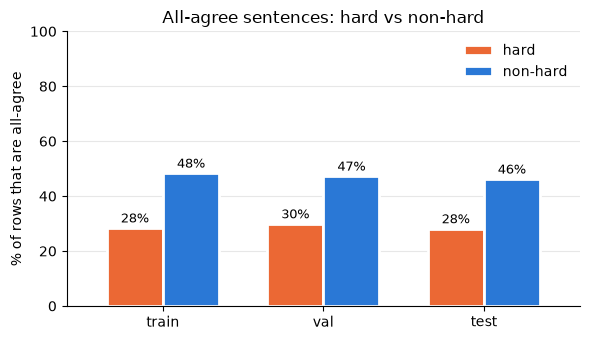

In [22]:
share = summary[["% all-agree (hard)", "% all-agree (non-hard)"]]
share.columns = ["hard", "non-hard"]

fig, ax = plt.subplots(figsize=(6, 3.5))
share.plot.bar(ax=ax, rot=0, width=0.7, color=["#eb6834", "#2a78d6"], edgecolor="white", linewidth=2)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
ax.set(ylabel="% of rows that are all-agree", ylim=(0, 100),
       title="All-agree sentences: hard vs non-hard")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/band_all_agree.png", dpi=150)
plt.show()


In [23]:
os.makedirs("../results/hard_samples", exist_ok=True)
for split, out in frames.items():
    out.to_csv(f"../results/hard_samples/band_{split}.csv", index=False)
    print(f"saved band_{split}.csv", out.shape)


saved band_train.csv (2901, 9)
saved band_val.csv (967, 9)
saved band_test.csv (968, 9)


## Save baseline to metrics.csv

Scored on val. `f1_hard` uses the band mask from above, not the old P20 set.

In [24]:
from utils.random_control import TEAM_COLUMNS, score_predictions, update_metrics_csv

val_hard_idx = np.flatnonzero(frames["val"].is_hard)
row = {"condition": "baseline", "embedding_config": "finbert_frozen", "architecture": "cnn_64",
       **score_predictions(y_val, val_probabilities, val_hard_idx)}
metrics = update_metrics_csv("../results/metrics.csv", pd.DataFrame([row])[TEAM_COLUMNS])
metrics


,condition,embedding_config,architecture,accuracy_overall,f1_overall,accuracy_hard,f1_hard,accuracy_nonhard,f1_nonhard,f1_negative,f1_neutral,f1_positive
0,targeted,finbert_finetuned,cnn_64,0.778697,0.709929,0.552577,0.477068,0.803908,0.741177,0.601528,0.847326,0.680935
1,targeted,finbert_frozen,cnn_64,0.798345,0.749777,0.624742,0.451130,0.817701,0.770973,0.686379,0.853857,0.709095
2,targeted,finbert_pretrained,transformer_finbert,0.857438,0.838963,0.582474,0.560134,NaN,NaN,NaN,NaN,NaN
3,random_control,finbert_finetuned,cnn_64,0.779731,0.710225,0.538776,0.466455,0.806904,0.743418,0.597771,0.847918,0.684985
4,random_control,finbert_frozen,cnn_64,0.798759,0.749278,0.618367,0.455547,0.819102,0.771809,0.683070,0.854425,0.710340
5,llm_benchmark,native_qwen,qwen2.5-7b-instruct,0.776600,0.786000,0.666700,0.674300,0.797300,0.808500,0.837400,0.793800,0.726700
6,baseline,tfidf_1-2gram,logreg,0.776629,0.717241,0.474227,0.390474,0.810345,0.760566,0.631579,0.845771,0.674374
7,baseline,random_init_100d,lstm_64_dropout,0.698035,0.464626,0.453608,0.319597,0.725287,0.480581,0.000000,0.832653,0.561224
8,baseline,random_frozen,cnn_64,0.741468,0.659704,0.422680,0.365168,0.777011,0.697802,0.545455,0.824096,0.609562
9,baseline,random_finetuned,cnn_64,0.783868,0.706000,0.536082,0.415473,0.811494,0.745897,0.580645,0.849725,0.687631
